# Frozen continuous study: saved results only
This notebook reads the completed frozen evaluation. It does not train models or launch another study. The primary was frozen before evaluation; software audit success is not scientific validity or DNH fidelity.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'research').is_dir())
OUT=ROOT/'review/continuous_initial'
if not (OUT/'execution.json').exists():
    OUT=ROOT/'results/frozen_continuous_initial'
execution=json.loads((OUT/'execution.json').read_text())
protocol=json.loads((OUT/'frozen_primary.json').read_text())
assert execution['status']=='completed'
assert len(execution['completed_runs'])==14
assert all(r['uninterrupted'] and r['model_state_continuity'] for r in execution['completed_runs'])
print('Frozen primary:',protocol['primary'])
print('Execution commit:',execution['git']['commit'])
print('Development / evaluation hours:',protocol['experiment']['development'],protocol['experiment']['steps'])
print('Customers:',[s['id'] for s in protocol['customers']])
display(pd.read_csv(OUT/'macro_metrics.csv'))
display(pd.read_csv(OUT/'metrics_by_series.csv'))
display(pd.read_csv(OUT/'costs_and_continuity.csv')[['series','seed','variant','wall_seconds','uninterrupted']])

Frozen primary: DNH-inspired:adaptive:descent
Execution commit: c86ff8edc972810436b68db842ec91651f878a9e
Development / evaluation hours: 2160 1008
Customers: ['T1', 'T10']


,model,macro_MASE,between_customer_MASE_sd
0,ARIMA,0.687671,0.145140
1,DNH-inspired:adaptive:descent,0.733095,0.201828
2,DNH-inspired:fixed:descent,0.733965,0.199164
3,persistence,0.722757,0.189405
4,seasonal_naive,0.951769,0.083964


,model,series,MAE,RMSE,MASE,seed_MASE_sd
0,ARIMA,T1,14.336398,20.097346,0.790300,NaN
1,ARIMA,T10,28.933793,45.660172,0.585041,NaN
2,DNH-inspired:adaptive:descent,T1,15.887569,22.667516,0.875809,0.008347
3,DNH-inspired:adaptive:descent,T10,29.197873,44.293312,0.590381,0.005399
4,DNH-inspired:fixed:descent,T1,15.869165,22.677196,0.874794,0.008451
5,DNH-inspired:fixed:descent,T10,29.334061,44.330531,0.593135,0.001660
6,persistence,T1,15.540675,24.368920,0.856686,NaN
7,persistence,T10,29.121032,45.652131,0.588827,NaN
8,seasonal_naive,T1,16.188492,24.800274,0.892398,NaN
9,seasonal_naive,T10,50.006944,85.036214,1.011140,NaN


,series,seed,variant,wall_seconds,uninterrupted
0,T1,NaN,baseline,31.372830,True
1,T1,17.0,adaptive,2.988190,True
2,T1,17.0,fixed,1.983049,True
3,T1,29.0,adaptive,3.021052,True
4,T1,29.0,fixed,2.629163,True
5,T1,43.0,adaptive,5.054488,True
6,T1,43.0,fixed,2.820651,True
7,T10,NaN,baseline,58.795644,True
8,T10,17.0,adaptive,3.251460,True
9,T10,17.0,fixed,2.258354,True


## Rolling and cumulative forecasting errors
The 24- and 168-hour windows require complete windows. Cumulative curves start at the first evaluation target. These are post-hoc summaries; no model state resets at plotting boundaries. Curves average model seeds, with no inferential intervals.

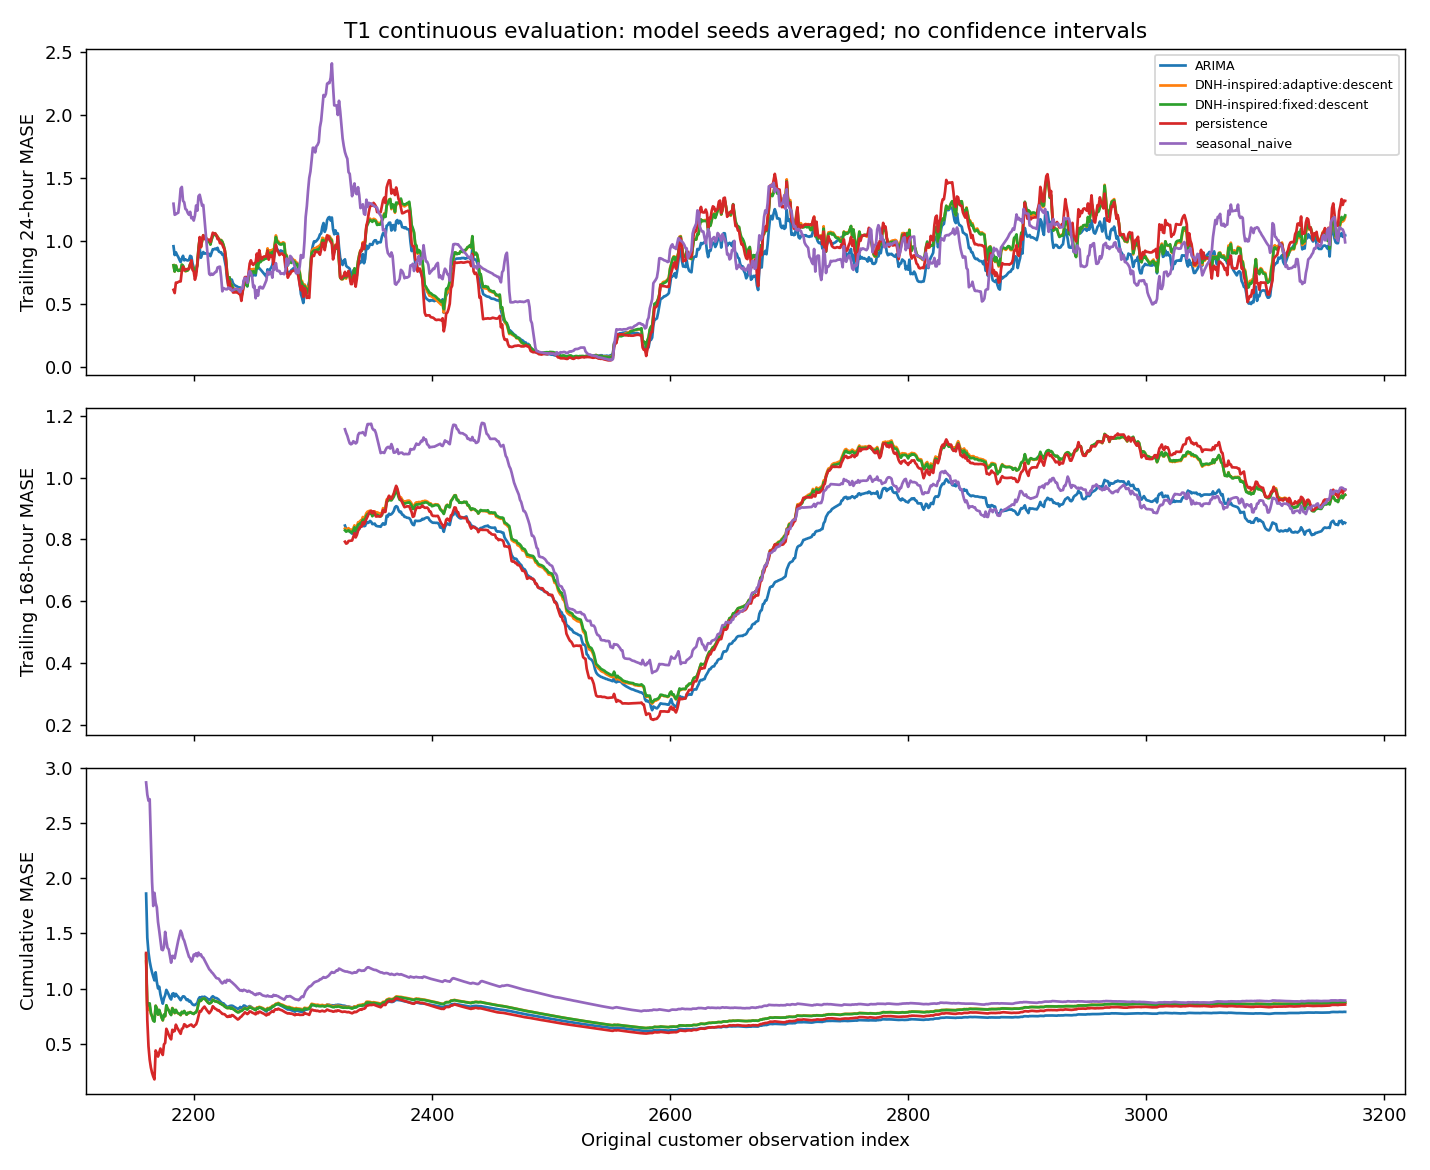

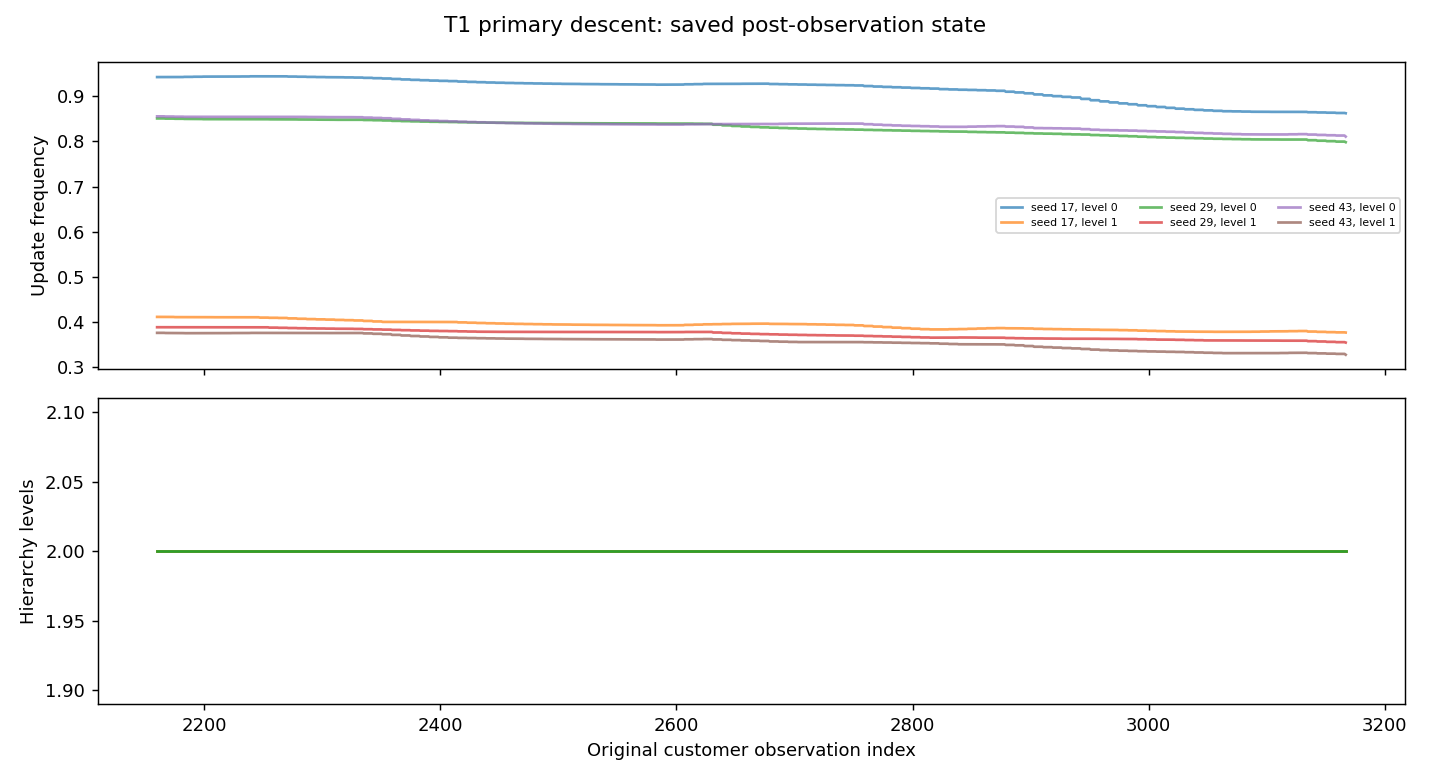

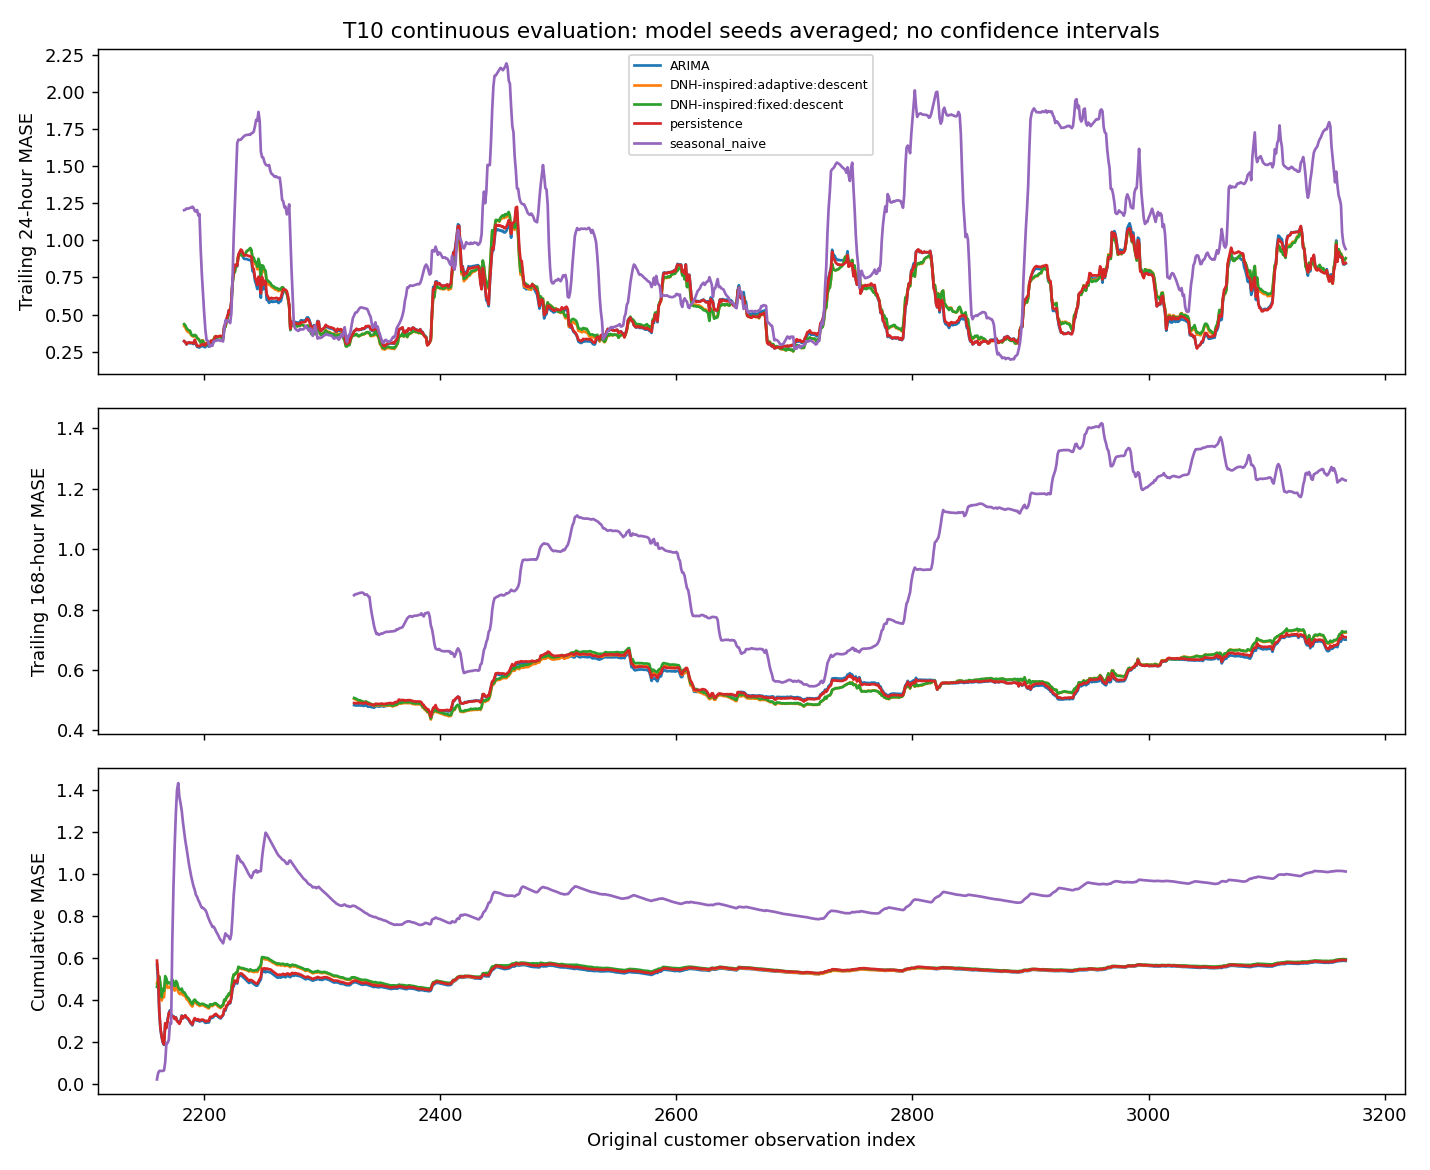

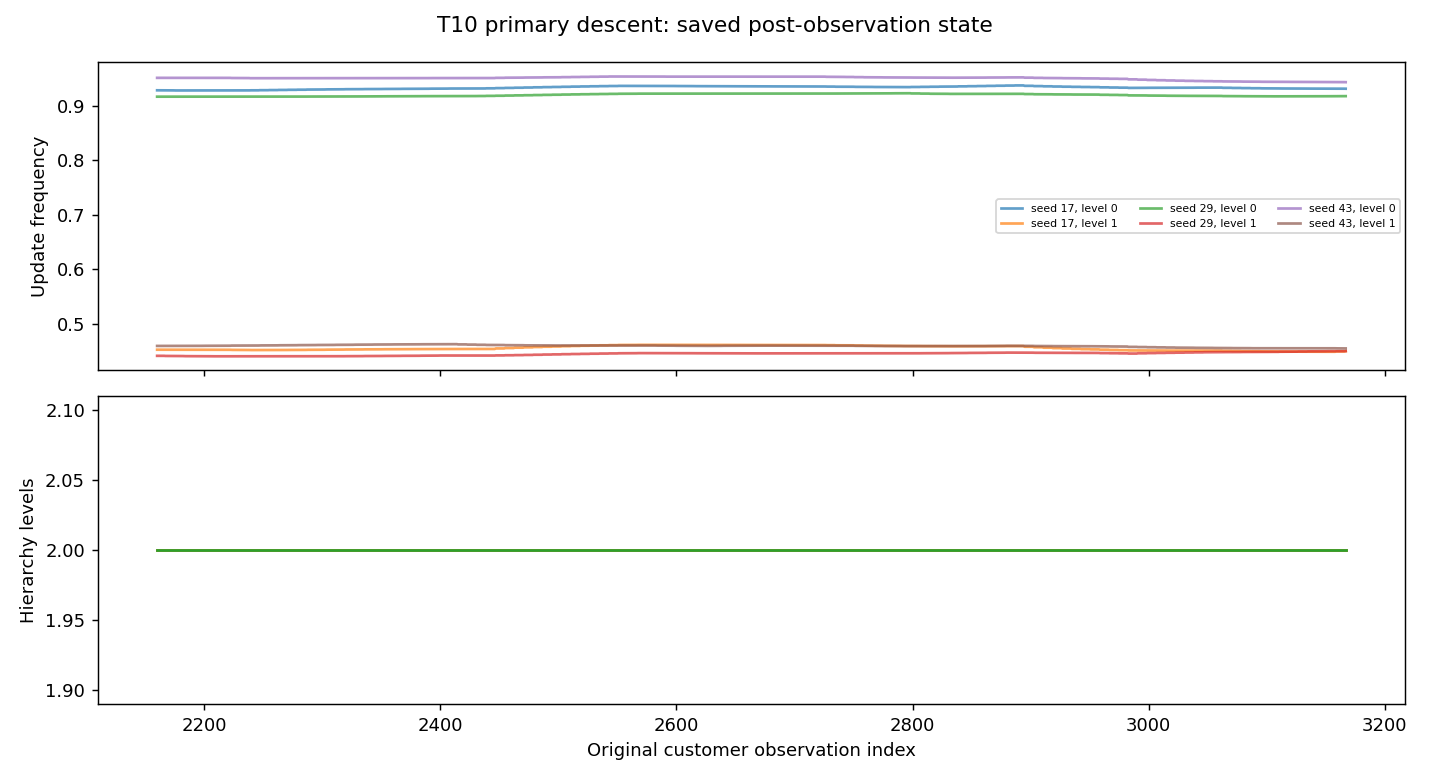

Primary did not beat ARIMA or persistence on macro MASE; no growth/pruning was proposed.


In [2]:
for sid in ['T1','T10']:
    display(Image(filename=str(OUT/'plots'/f'{sid}_errors.png')))
    display(Image(filename=str(OUT/'plots'/f'{sid}_structure.png')))
print('Primary did not beat ARIMA or persistence on macro MASE; no growth/pruning was proposed.')

## Audits and retained limitations
The study verifies freeze provenance, software chronology, one-segment evaluation, final counts, errors and ARIMA scheduling. It cannot establish full-calendar scientific validity or faithful DNH behavior. A fixed hierarchy freezes both structure and frequencies, so it is not a growth-only ablation.

In [3]:
audit=json.loads((OUT/'study_audit.json').read_text())
display(pd.DataFrame(audit['checks']))
display(pd.DataFrame(audit['skipped']))
ledger=pd.read_csv(OUT/'ARIMA_update_ledger.csv')
display(ledger.groupby(['series','method','success']).size().rename('count').reset_index())
display(pd.read_csv(OUT/'structural_counts.csv').query("phase=='evaluation'"))

,name,status
0,frozen_before_evaluation,pass
1,protocol_hash_matches_execution,pass
2,all_14_runs_completed_uninterrupted,pass
3,T1/baseline/per_experiment_audit,pass
4,T1/17/adaptive/per_experiment_audit,pass
5,T1/17/fixed/per_experiment_audit,pass
6,T1/29/adaptive/per_experiment_audit,pass
7,T1/29/fixed/per_experiment_audit,pass
8,T1/43/adaptive/per_experiment_audit,pass
9,T1/43/fixed/per_experiment_audit,pass


,name,reason
0,per_experiment_full_behavioral_replay,Resume invariance tested on small synthetic ca...
1,scientific_validity_DNH_fidelity_full_calendar,Not established by software checks or two-cust...


,series,method,success,count
0,T1,filter_append,True,1002
1,T1,parameter_refit,True,6
2,T10,filter_append,True,1002
3,T10,parameter_refit,True,6


,phase,operation,status,reason,count,series,seed,variant
3,evaluation,growth,not_proposed,loss_threshold_not_met,799,T1,17,adaptive
4,evaluation,growth,not_proposed,patience_not_met,209,T1,17,adaptive
5,evaluation,pruning,not_proposed,no_eligible_non_root_level,1008,T1,17,adaptive
8,evaluation,growth,disabled,fixed_hierarchy,1008,T1,17,fixed
9,evaluation,pruning,disabled,fixed_hierarchy,1008,T1,17,fixed
13,evaluation,growth,not_proposed,loss_threshold_not_met,803,T1,29,adaptive
14,evaluation,growth,not_proposed,patience_not_met,205,T1,29,adaptive
15,evaluation,pruning,not_proposed,no_eligible_non_root_level,1008,T1,29,adaptive
18,evaluation,growth,disabled,fixed_hierarchy,1008,T1,29,fixed
19,evaluation,pruning,disabled,fixed_hierarchy,1008,T1,29,fixed
